<a href="https://colab.research.google.com/github/yeongwonshin/montecarloSimul/blob/main/%E1%84%86%E1%85%A9%E1%86%AB%E1%84%90%E1%85%A6%E1%84%8F%E1%85%A1%E1%84%85%E1%85%B3%E1%86%AF%E1%84%85%E1%85%A9_%E1%84%89%E1%85%B5%E1%86%AF%E1%84%89%E1%85%B3%E1%86%B8%E1%84%8B%E1%85%AD%E1%86%BC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 코드 예시) Random 함수


In [ ]:
import random

In [ ]:
#random.random() -> 0.0에서 1.0사이의 실수 중에서 난수값 리턴
print(random.random())
# ex) 0.2664520652284096

#random.uniform(a, b) -> 괄호 안 두 수 사이의 실수 중에서 난수값을 리턴
print(random.uniform(10, 30))
# ex) 28.038707445386397

#random.randint(a, b) -> 괄호 안 두 수 사이의 정수 중에서 난수값을 리턴
print(random.randint(100,200))
# ex) 106

#random.choice(sample) 함수 -> sample에서 무작위로 하나를 선택하여 리턴
data = [1, 2, 3, 4, 5, 6, 7]
print(random.choice(data))
# ex) 5

#random.sample(sample, n) -> 입력으로 받은 sample 에서 정한 개수만큼  무작위로 뽑아 리턴함
data = [1, 2, 3, 4, 'apple', 'banna']
print(random.sample(data, 3))
# ex) ['apple', 2, 3]
print(random.sample(data, 3))
# ex) ['apple', 3, 'banna']
print(random.sample(data, 5))
# ex) [2, 3, 1, 'apple', 4]

# 실습1. 난수 히스토그램 그리기(파이썬 random 모듈)

In [1]:
# import packages
import matplotlib.pyplot as plt
from tqdm import tqdm # optional
import random

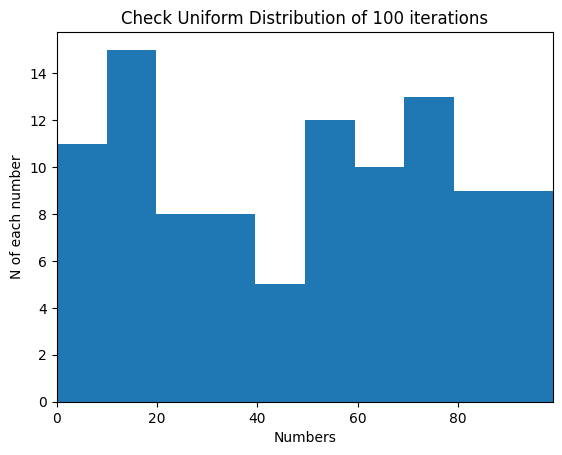

In [2]:
# 100번 수행
num_iterations = 100
random_integers = []

## write answer
##
##
##
##
##
##
##
for i in range(num_iterations):
    num = random.randint(0, 99)
    random_integers.append(num)


fig = plt.figure()
plt.hist(random_integers)
plt.title(f"Check Uniform Distribution of {num_iterations} iterations")
plt.xlabel("Numbers")
plt.ylabel("N of each number")
plt.xlim([0, 99])
plt.show()

# 실습 2. Linear Congruential Generator(LCG) 구현  

X_(n+1) = (aX_n+C) mod m

LCG는 다음과 같은 인자들로 유일하게 결정됨  
  - 0 < m, 0 < a < m, 0 <= c < m, 0<=초기값 < m  

최대 주기 m을 가지기 위한 필요충분조건  

  - c와 m이 서로소, a-1이 m의 모든 소인수로 나뉨
  - m이 4의 배수면 a-1도 4의 배수

In [6]:
def lcg(seed, loop, m=2**32, a=214013, c=2531011):
    for i in range(loop):
        # write answer
        seed = (a * seed + c) % m

        yield seed

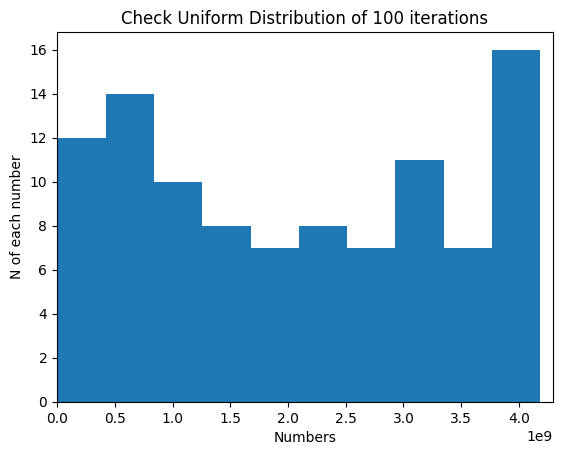

In [7]:
num_iterations = 100
random_generator = lcg(seed=13, loop=num_iterations, m=2**32)
random_integers = []



## write answer
##
##
##
##
##
##
##

for num in random_generator:
    random_integers.append(num)




fig = plt.figure()
plt.hist(random_integers)
plt.title(f"Check Uniform Distribution of {num_iterations} iterations")
plt.xlabel("Numbers")
plt.ylabel("N of each number")
plt.xlim([0, 2**32])
plt.show()

# 실습 2-2 난수들 중 Uniform Distribution 확인  


In [9]:
# LCG

from collections import defaultdict

for num_iterations in [1000, 10000, 100000]:
    random_generator = lcg(seed=13, loop=num_iterations, m=2**32)
    frequency = defaultdict(int)

    for _ in range(num_iterations):
        num = next(random_generator) % 100
        frequency[num] += 1

    error = 0
    for i in range(100):
        actual_prob = frequency[i] / num_iterations
        expected_prob = 1 / 100
        error += abs(actual_prob - expected_prob)

    error /= 100

    print(f"LCG 시행횟수 {num_iterations}에서의 uniform distribution 오차 : {error}")


LCG 시행횟수 1000에서의 uniform distribution 오차 : 0.002540000000000002
LCG 시행횟수 10000에서의 uniform distribution 오차 : 0.00079
LCG 시행횟수 100000에서의 uniform distribution 오차 : 0.00023279999999999989


In [10]:
# 메르센 트위스터

import random
from collections import defaultdict

for num_iterations in [1000, 10000, 100000]:
    random.seed(13)
    frequency = defaultdict(int)

    for _ in range(num_iterations):
        num = random.randint(0, 99)
        frequency[num] += 1

    error = 0
    for i in range(100):
        actual_prob = frequency[i] / num_iterations
        expected_prob = 1 / 100
        error += abs(actual_prob - expected_prob)

    error /= 100

    print(f"메르센 트위스터 시행횟수 {num_iterations}에서의 uniform distribution 오차 : {error}")


메르센 트위스터 시행횟수 1000에서의 uniform distribution 오차 : 0.0023400000000000014
메르센 트위스터 시행횟수 10000에서의 uniform distribution 오차 : 0.0007180000000000003
메르센 트위스터 시행횟수 100000에서의 uniform distribution 오차 : 0.0002598000000000001


# 실습 3. 주사위 합이 8인 경우

In [11]:
# 출력시 컬러 지원 가능 모듈 설치
!pip install termcolor
from termcolor import colored
!pip install colorama
from colorama import init, Fore, Back, Style


In [12]:
def roll_dice():
    dice1 = random.randint(1, 6)
    dice2 = random.randint(1, 6)
    return dice1, dice2

In [13]:
dice_tries = []
num_iterations = 100
hits = 0

for _ in range(num_iterations):
    dice1, dice2 = roll_dice()
    dice_tries.append((dice1, dice2))

    if dice1 + dice2 == 8:
        hits += 1

print("=" * 100)
print(colored("* 두 주사위의 합이 8인 경우에는 cyan 색의 음영이 들어가 있음 *", 'red'))

for i in range(num_iterations):
    dice1, dice2 = dice_tries[i]
    result = f"{i+1}회: {dice1} + {dice2} = {dice1+dice2}"

    if dice1 + dice2 == 8:
        print(colored(result, 'black', 'on_cyan'))
    else:
        print(result)

print(colored("\n실제 값 : 0.138889", "red"))
print(colored(f"계산된 값 : {round(hits / num_iterations, 6)}", "red"))
print(colored(f"오차율 : {abs(hits / num_iterations - 5/36) / (5/36) * 100} %", "red"))
print("=" * 100)

* 두 주사위의 합이 8인 경우에는 cyan 색의 음영이 들어가 있음 *
1회: 2 + 5 = 7
2회: 5 + 2 = 7
3회: 6 + 2 = 8
4회: 3 + 3 = 6
5회: 2 + 4 = 6
6회: 1 + 5 = 6
7회: 1 + 4 = 5
8회: 3 + 1 = 4
9회: 3 + 5 = 8
10회: 2 + 5 = 7
11회: 5 + 6 = 11
12회: 2 + 4 = 6
13회: 2 + 5 = 7
14회: 2 + 2 = 4
15회: 5 + 1 = 6
16회: 2 + 2 = 4
17회: 4 + 6 = 10
18회: 4 + 5 = 9
19회: 3 + 6 = 9
20회: 1 + 5 = 6
21회: 4 + 1 = 5
22회: 1 + 5 = 6
23회: 3 + 5 = 8
24회: 5 + 1 = 6
25회: 4 + 4 = 8
26회: 5 + 2 = 7
27회: 2 + 6 = 8
28회: 4 + 5 = 9
29회: 1 + 6 = 7
30회: 6 + 4 = 10
31회: 6 + 3 = 9
32회: 3 + 1 = 4
33회: 5 + 3 = 8
34회: 3 + 5 = 8
35회: 3 + 1 = 4
36회: 2 + 3 = 5
37회: 2 + 1 = 3
38회: 3 + 4 = 7
39회: 5 + 3 = 8
40회: 3 + 1 = 4
41회: 3 + 2 = 5
42회: 3 + 5 = 8
43회: 1 + 5 = 6
44회: 2 + 6 = 8
45회: 3 + 6 = 9
46회: 5 + 3 = 8
47회: 4 + 2 = 6
48회: 3 + 6 = 9
49회: 4 + 6 = 10
50회: 6 + 2 = 8
51회: 6 + 3 = 9
52회: 5 + 3 = 8
53회: 6 + 2 = 8
54회: 3 + 3 = 6
55회: 6 + 2 = 8
56회: 1 + 4 = 5
57회: 1 + 3 = 4
58회: 5 + 2 = 7
59회: 6 + 6 = 12
60회: 2 + 1 = 3
61회: 2 + 1 = 3
62회: 4 + 6 = 10
63회: 4 + 6 = 10
64회: 5 + 1 = 6
6